# Actividad 2 de Estadística

**Tecnológico de Monterrey**
Profesor: Luis Daniel Mendoza Morales

Nombre: ______________________________________   Matrícula: ______________

---


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import norm, t, f, chi2, chi2_contingency, chisquare, f_oneway

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
AZUL, CLARO = "#00209F", "#AFC6E9"

---
## Los datos

Cinco conjuntos ya cargados. El primero es grande: 200 observaciones, así que
tendrás que trabajarlo necesariamente con pandas. **No modifiques esta celda.**

In [2]:
# A - Tiempo de atencion en la barra, en minutos, de 200 clientes
atencion = pd.Series(name="min", data=[
    11.8, 15.6, 17.7, 18.5, 10.0, 19.8, 11.7, 12.8, 13.8, 25.7, 16.8, 10.7, 16.6, 14.2, 13.7, 13.9, 11.8, 14.9, 19.0, 15.2,
    11.2, 12.6, 17.7, 19.5, 11.3, 13.0, 12.4, 14.4, 10.3, 13.2, 13.5, 19.4, 15.9, 12.3, 15.4, 13.8, 27.2, 14.4, 21.3, 13.0,
    12.7, 19.3, 11.4, 13.3, 12.6, 12.4, 13.9, 14.6, 20.0, 14.5, 10.5, 14.5, 12.1, 16.7, 17.1, 19.0, 15.3, 11.3, 15.7, 8.6,
    14.5, 13.8, 21.2, 22.9, 13.8, 12.5, 15.8, 12.3, 9.6, 11.9, 14.5, 22.6, 11.4, 13.6, 15.0, 17.7, 15.7, 16.7, 16.4, 11.3,
    13.3, 14.0, 12.4, 13.5, 13.3, 11.7, 15.4, 16.7, 16.2, 14.5, 28.9, 14.7, 11.5, 17.1, 16.3, 12.2, 10.4, 10.2, 13.8, 16.9,
    14.0, 14.6, 16.6, 13.4, 14.2, 15.7, 22.1, 16.4, 10.8, 14.7, 12.7, 21.9, 12.4, 14.2, 18.0, 24.9, 12.0, 10.7, 9.8, 13.8,
    11.7, 12.9, 9.8, 17.6, 12.0, 12.6, 18.7, 16.3, 13.5, 11.2, 16.1, 10.3, 12.6, 12.2, 8.1, 14.6, 13.7, 13.2, 22.9, 17.1,
    11.7, 19.3, 14.2, 14.9, 10.7, 13.0, 9.9, 10.0, 18.1, 28.0, 25.0, 14.6, 12.8, 15.6, 11.3, 12.9, 12.7, 11.5, 12.7, 14.3,
    13.1, 19.5, 10.6, 12.2, 17.8, 10.7, 15.6, 14.7, 14.6, 11.7, 12.7, 15.2, 16.3, 11.3, 15.4, 14.3, 12.6, 13.7, 17.0, 19.4,
    14.2, 10.8, 26.7, 14.9, 12.7, 19.6, 16.7, 14.7, 20.4, 9.7, 8.8, 10.5, 9.0, 12.1, 13.2, 8.2, 11.1, 11.4, 13.3, 15.0
])

# B - Calificacion de satisfaccion (1 a 10) de 10 clientes en cada sucursal
satisfaccion = pd.DataFrame({
    "Centro": [ 7,  8, 6,  9, 7, 8, 7, 6,  8, 7],
    "Norte":  [ 9,  8, 9, 10, 8, 9, 9, 8, 10, 9],
    "Sur":    [ 6,  7, 5,  6, 7, 6, 5, 7,  6, 6]})

# C - Minutos que el cliente permanece y consumo total, en pesos, de 30 visitas
consumo = pd.DataFrame({
    "minutos": [12, 15, 18, 20, 22, 25, 26, 28, 30, 32, 34, 35, 38, 40, 42,
                44, 45, 48, 50, 52, 54, 55, 58, 60, 62, 65, 68, 70, 72, 75],
    "pesos":   [58, 134, 108, 76, 92, 144, 102, 160, 136, 154, 181, 174, 162, 188, 218,
                170, 197, 214, 181, 196, 209, 217, 259, 231, 266, 257, 213, 301, 258, 316]})

# D - Bebida preferida: proporcion historica y lo observado en 300 clientes
bebidas = pd.DataFrame({
    "bebida":      ["cafe", "te", "frappe", "otros"],
    "p_historica": [0.40, 0.25, 0.20, 0.15],
    "observados":  [136, 66, 63, 35]})

# E - Metodo de pago por turno, 440 operaciones (tabla de contingencia)
pagos = pd.DataFrame({
    "efectivo": [62, 45, 28],
    "tarjeta":  [48, 60, 52],
    "app":      [30, 45, 70]}, index=["manana", "tarde", "noche"])

print("atencion:", atencion.size, "| satisfaccion:", satisfaccion.shape,
      "| consumo:", consumo.shape, "| bebidas:", bebidas["observados"].sum(),
      "| pagos:", pagos.values.sum())

atencion: 200 | satisfaccion: (10, 3) | consumo: (30, 2) | bebidas: 300 | pagos: 440



## Ejercicio 1 — El tiempo de atención en la barra

Trabaja con el conjunto **`atencion`**: los minutos que tardó el servicio para
**200 clientes**. Con este tamaño de muestra ya no hay forma de hacer nada a mano,
que es justo el punto.

**Responde:**

1. Calcula la **media**, la **mediana**, la **desviación estándar** y el
   **coeficiente de variación**. La media resulta mayor que la mediana:
   explica qué lo provoca y qué indica sobre la forma de la distribución.
2. Calcula **Q1, Q2, Q3**, el **rango interquartílico** y el **percentil 90**.
   Aplica el **criterio del rango interquartílico**: reporta los dos límites,
   **cuántas** observaciones quedan fuera y de qué lado.


In [3]:
# Ejercicio 1
# 1) Medidas de centralización y dispersión
media = atencion.mean()
mediana = atencion.median()
desv = atencion.std()          # desviación estándar muestral
cv = desv / media * 100        # coeficiente de variación en %

print("Media:", round(media, 2), "min")
print("Mediana:", round(mediana, 2), "min")
print("Desviación estándar:", round(desv, 2), "min")
print("Coeficiente de variación:", round(cv, 2), "%")

Media: 14.61 min
Mediana: 13.85 min
Desviación estándar: 3.78 min
Coeficiente de variación: 25.89 %


**¿Por qué la media es mayor que la mediana?**
Porque hay algunos clientes que tardaron mucho (de 22 a 29 minutos). Esos valores grandes
jalan la media hacia arriba, pero a la mediana casi no le afectan. Eso quiere decir que la
distribución tiene **sesgo a la derecha** (cola larga hacia los tiempos altos).

In [4]:
# 2) Cuartiles, rango intercuartílico y percentil 90
q1 = atencion.quantile(0.25)
q2 = atencion.quantile(0.50)
q3 = atencion.quantile(0.75)
ric = q3 - q1
p90 = atencion.quantile(0.90)

print("Q1:", round(q1, 2))
print("Q2:", round(q2, 2))
print("Q3:", round(q3, 2))
print("Rango intercuartílico:", round(ric, 2))
print("Percentil 90:", round(p90, 2))

# Criterio del rango intercuartílico
lim_inf = q1 - 1.5 * ric
lim_sup = q3 + 1.5 * ric
abajo = atencion[atencion < lim_inf]
arriba = atencion[atencion > lim_sup]

print()
print("Límite inferior:", round(lim_inf, 2))
print("Límite superior:", round(lim_sup, 2))
print("Atípicos abajo:", len(abajo))
print("Atípicos arriba:", len(arriba))
print("Valores atípicos:", sorted(arriba))

Q1: 12.18
Q2: 13.85
Q3: 16.3
Rango intercuartílico: 4.13
Percentil 90: 19.41

Límite inferior: 5.99
Límite superior: 22.49
Atípicos abajo: 0
Atípicos arriba: 10
Valores atípicos: [22.6, 22.9, 22.9, 24.9, 25.0, 25.7, 26.7, 27.2, 28.0, 28.9]


Hay **10 valores atípicos y todos están del lado de arriba** (tiempos largos). Ninguno queda
por debajo del límite inferior, lo que confirma el sesgo a la derecha.

/tmp/ipykernel_432/3648043921.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(atencion, vert=False)


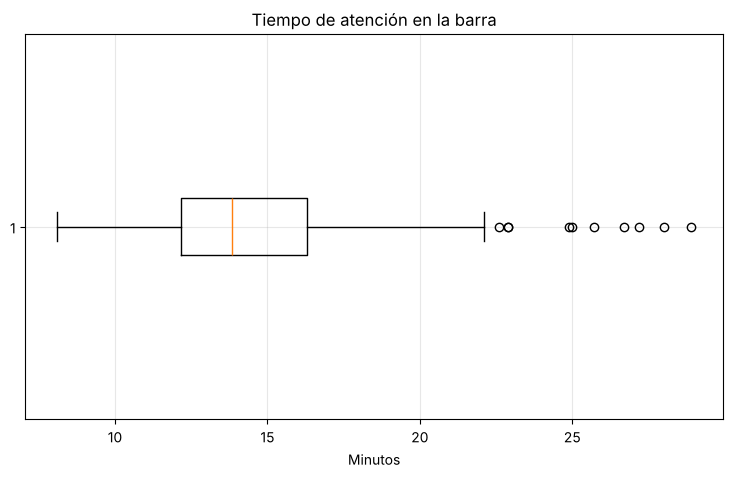

Bigote inferior llega a: 8.1
Bigote superior llega a: 22.1


In [5]:
# 3) Diagrama de caja y bigote
plt.boxplot(atencion, vert=False)
plt.title("Tiempo de atención en la barra")
plt.xlabel("Minutos")
plt.show()

# Los bigotes llegan hasta el dato más chico y el más grande que no son atípicos
bigote_inf = atencion[atencion >= lim_inf].min()
bigote_sup = atencion[atencion <= lim_sup].max()
print("Bigote inferior llega a:", bigote_inf)
print("Bigote superior llega a:", bigote_sup)

**¿Se eliminan o se conservan los tiempos largos?**
Yo los **conservo**. Que un dato sea atípico no significa que esté mal: no hay razón para pensar
que fueron errores de captura, son clientes reales que esperaron mucho. Si los quito, la media
y la desviación bajarían y la sucursal se vería mejor de lo que realmente es. Además, como la
distribución es sesgada, para describir el "cliente típico" ya tengo la mediana, que no se ve
afectada por ellos.

Para la operación, esos clientes son los que **esperaron de más** (de 22 a 29 min). Son los que
probablemente se van molestos, así que conviene revisar qué pasó en esos casos (horas pico,
pedidos complicados, falta de personal).


## Ejercicio 2 — Distribución normal

El proveedor envasa el café molido en sobres. El peso del sobre sigue una
distribución **normal con media 250 g y desviación estándar 4 g**.

**Responde:**

1. Calcula las tres probabilidades siguientes, y di en una frase qué significa
   cada una en términos de sobres:
   - que un sobre pese **menos de 245 g**
   - que pese **entre 248 y 254 g**
   - que pese **más de 256 g**
2. La cadena quiere rechazar el 10 % de los sobres más ligeros. ¿**Por debajo de
   qué peso** debe poner el corte? Este es el problema inverso: se parte del área
   y se busca el valor, no al revés.

In [6]:
# Ejercicio 2
mu = 250
sigma = 4

# P(X < 245)
p1 = norm.cdf(245, mu, sigma)
# P(248 < X < 254)
p2 = norm.cdf(254, mu, sigma) - norm.cdf(248, mu, sigma)
# P(X > 256)
p3 = 1 - norm.cdf(256, mu, sigma)

print("P(X < 245) =", round(p1, 4))
print("P(248 < X < 254) =", round(p2, 4))
print("P(X > 256) =", round(p3, 4))

P(X < 245) = 0.1056
P(248 < X < 254) = 0.5328
P(X > 256) = 0.0668


- **Menos de 245 g:** aprox. 10.6 %, o sea, unos 11 de cada 100 sobres pesan menos de 245 g.
- **Entre 248 y 254 g:** aprox. 53.3 %, un poco más de la mitad de los sobres cae en ese rango.
- **Más de 256 g:** aprox. 6.7 %, unos 7 de cada 100 sobres pesan más de 256 g.

In [7]:
# Problema inverso: buscar el peso que deja el 10 % más ligero por debajo
corte = norm.ppf(0.10, mu, sigma)
print("Peso de corte:", round(corte, 2), "g")

Peso de corte: 244.87 g


El corte debe ponerse en **244.87 g**: todo sobre que pese menos de eso se rechaza, y eso
equivale al 10 % de los sobres más ligeros.


## Ejercicio 3 — Prueba de hipótesis para una media

El estándar corporativo dice que el tiempo promedio de atención es de
**15 minutos**. La gerencia de esta sucursal sostiene que aquí se atiende
**más rápido** que el estándar, y quiere demostrarlo con los 200 clientes del
conjunto **`atencion`**.

**Responde:**

1. Plantea **H₀ y H₁**, y di si la prueba es de una o de dos colas, con su
   justificación. Calcula el **error estándar**, el **estadístico de prueba** y
   el **valor p**. Como σ es desconocida, se usa la distribución t.
2. Toma la decisión con α = 0.05 y escribe la conclusión. Después responde:
   ¿la gerencia puede afirmar que su sucursal es más rápida que el estándar?
   Cuida la diferencia entre *no rechazar* y *demostrar que H₀ es cierta*.

**Hipótesis**

- H₀: μ ≥ 15 (la sucursal no es más rápida que el estándar)
- H₁: μ < 15 (la sucursal atiende más rápido)

Es una prueba de **una cola (cola izquierda)**, porque la gerencia no dice "diferente",
dice "más rápido", o sea, un tiempo **menor** a 15 minutos.

In [8]:
# Ejercicio 3
n = len(atencion)
media = atencion.mean()
s = atencion.std()
mu0 = 15
alfa = 0.05

error_est = s / np.sqrt(n)
t_calc = (media - mu0) / error_est
gl = n - 1
valor_p = t.cdf(t_calc, gl)      # cola izquierda

print("n =", n)
print("Media muestral:", round(media, 3))
print("Error estándar:", round(error_est, 4))
print("Estadístico t:", round(t_calc, 4))
print("Grados de libertad:", gl)
print("Valor p:", round(valor_p, 4))

if valor_p < alfa:
    print("Se rechaza H0")
else:
    print("No se rechaza H0")

n = 200
Media muestral: 14.612
Error estándar: 0.2675
Estadístico t: -1.4526
Grados de libertad: 199
Valor p: 0.074
No se rechaza H0


**Conclusión:** el valor p (0.074) es mayor que α = 0.05, así que **no se rechaza H₀**. Con
estos 200 clientes **no hay evidencia suficiente** para decir que la sucursal atiende en menos de
15 minutos en promedio.

**¿La gerencia puede afirmar que es más rápida?** No. La media de la muestra (14.6 min) sí es un
poco menor a 15, pero la diferencia no es lo bastante grande para descartar que sea por azar.
Ojo: no rechazar H₀ **tampoco demuestra** que el promedio sea 15 o más; solo significa que los
datos no alcanzan para probar lo que dice la gerencia.


## Ejercicio 4 — Bondad de ajuste

El conjunto **`bebidas`** trae la distribución histórica de la bebida preferida
y lo que se observó en una muestra de **300 clientes** de este mes.

| bebida | café | té | frappé | otros |
|---|---|---|---|---|
| proporción histórica | 0.40 | 0.25 | 0.20 | 0.15 |
| observados este mes | 136 | 66 | 63 | 35 |

**Responde:**

1. Plantea las hipótesis. Calcula las **frecuencias esperadas** y **verifica que
   todas lleguen a 5** antes de seguir. Después calcula el estadístico de prueba
   y los grados de libertad.
2. Decide con α = 0.05 y concluye: ¿cambiaron las preferencias respecto al
   histórico? Reporta además **qué categoría se aparta más** de lo esperado y
   en qué dirección.

**Hipótesis**

- H₀: las preferencias de este mes siguen la distribución histórica (40 %, 25 %, 20 %, 15 %).
- H₁: las preferencias de este mes son diferentes a la distribución histórica.

In [9]:
# Ejercicio 4
n = bebidas["observados"].sum()
bebidas["esperados"] = bebidas["p_historica"] * n
print(bebidas)

# Condición: todas las esperadas deben ser al menos 5
print()
print("¿Todas las esperadas son >= 5?", (bebidas["esperados"] >= 5).all())

   bebida  p_historica  observados  esperados
0    cafe         0.40         136      120.0
1      te         0.25          66       75.0
2  frappe         0.20          63       60.0
3   otros         0.15          35       45.0

¿Todas las esperadas son >= 5? True


In [10]:
chi_calc, valor_p = chisquare(bebidas["observados"], bebidas["esperados"])
gl = len(bebidas) - 1
alfa = 0.05

print("Estadístico chi cuadrada:", round(chi_calc, 4))
print("Grados de libertad:", gl)
print("Valor p:", round(valor_p, 4))

if valor_p < alfa:
    print("Se rechaza H0")
else:
    print("No se rechaza H0")

# ¿Qué categoría se aparta más?
bebidas["diferencia"] = bebidas["observados"] - bebidas["esperados"]
bebidas["aporte_chi"] = bebidas["diferencia"]**2 / bebidas["esperados"]
print()
print(bebidas[["bebida", "observados", "esperados", "diferencia", "aporte_chi"]])

Estadístico chi cuadrada: 5.5856
Grados de libertad: 3
Valor p: 0.1336
No se rechaza H0

   bebida  observados  esperados  diferencia  aporte_chi
0    cafe         136      120.0        16.0    2.133333
1      te          66       75.0        -9.0    1.080000
2  frappe          63       60.0         3.0    0.150000
3   otros          35       45.0       -10.0    2.222222


**Conclusión:** el valor p (0.134) es mayor que 0.05, así que **no se rechaza H₀**. No hay
evidencia de que las preferencias hayan cambiado respecto al histórico; las diferencias que se ven
pueden ser por azar de la muestra.

**Categoría que más se aparta:** "otros" es la que más aporta al estadístico (2.22): se esperaban 45
y se observaron 35, o sea, **10 menos de lo esperado**. Muy cerca está el café (aporte 2.13), que
salió **16 por arriba** de lo esperado (136 contra 120). Aun así, ninguna de estas diferencias es
suficiente para decir que algo cambió.


## Ejercicio 5 — Prueba de independencia

El conjunto **`pagos`** es una tabla de contingencia con **440 operaciones**,
clasificadas por turno y por método de pago.

| | efectivo | tarjeta | app |
|---|---|---|---|
| **mañana** | 62 | 48 | 30 |
| **tarde** | 45 | 60 | 45 |
| **noche** | 28 | 52 | 70 |

**Responde:**

1. Plantea las hipótesis **en palabras**, en el contexto del problema. Calcula
   las frecuencias esperadas, verifica la condición, y obtén el estadístico y
   los grados de libertad.
2. Decide con α = 0.05 y concluye. Si hay relación, describe **en qué sentido
   va**: compara los porcentajes de cada método dentro de cada turno y di qué
   cambia de la mañana a la noche.

**Hipótesis**

- H₀: el método de pago **no depende** del turno (son independientes).
- H₁: el método de pago **sí depende** del turno (hay relación).

In [11]:
# Ejercicio 5
chi_calc, valor_p, gl, esperadas = chi2_contingency(pagos)
esperadas = pd.DataFrame(esperadas, index=pagos.index, columns=pagos.columns)
alfa = 0.05

print("Frecuencias esperadas:")
print(esperadas.round(2))
print()
print("¿Todas las esperadas son >= 5?", (esperadas >= 5).all().all())
print()
print("Estadístico chi cuadrada:", round(chi_calc, 4))
print("Grados de libertad:", gl)
print("Valor p:", valor_p)

if valor_p < alfa:
    print("Se rechaza H0")
else:
    print("No se rechaza H0")

Frecuencias esperadas:
        efectivo  tarjeta    app
manana     42.95    50.91  46.14
tarde      46.02    54.55  49.43
noche      46.02    54.55  49.43

¿Todas las esperadas son >= 5? True

Estadístico chi cuadrada: 30.9548
Grados de libertad: 4
Valor p: 3.1270405977766535e-06
Se rechaza H0


In [12]:
# Porcentaje de cada método dentro de cada turno (cada renglón suma 100 %)
porcentajes = pagos.div(pagos.sum(axis=1), axis=0) * 100
print(porcentajes.round(1))

        efectivo  tarjeta   app
manana      44.3     34.3  21.4
tarde       30.0     40.0  30.0
noche       18.7     34.7  46.7


**Conclusión:** el valor p es muy pequeño (≈ 0.000003), mucho menor que 0.05, así que **se
rechaza H₀**. El método de pago **sí está relacionado** con el turno.

**¿En qué sentido?** En la mañana domina el **efectivo** (44.3 %) y la app es lo menos usado
(21.4 %). Conforme avanza el día esto se invierte: en la noche la **app** pasa a ser lo más usado
(46.7 %) y el efectivo baja a 18.7 %. La tarjeta se mantiene más o menos estable (34 % a 40 %) en
los tres turnos.


## Ejercicio 6 — Análisis de varianza

El conjunto **`satisfaccion`** trae la calificación de 1 a 10 que dieron
**10 clientes en cada una** de las tres sucursales.

**Responde:**

1. Plantea las hipótesis del ANOVA de un factor. Calcula las **medias de cada
   sucursal** y la **media general**, arma la **tabla ANOVA** completa —suma de
   cuadrados, grados de libertad, cuadrados medios y F— y obtén el valor p.
2. Decide con α = 0.05 y concluye. Después explica qué **no** te dice la prueba:
   si se rechaza H₀, ¿puedes afirmar cuál sucursal es distinta de cuál? Apóyate
   en las medias para decir qué sospechas, y aclara qué haría falta para
   confirmarlo.

**Hipótesis**

- H₀: μ_Centro = μ_Norte = μ_Sur (las tres sucursales tienen la misma satisfacción promedio).
- H₁: al menos una sucursal tiene una media distinta.

In [13]:
# Ejercicio 6
medias = satisfaccion.mean()
media_general = satisfaccion.values.mean()
print("Medias por sucursal:")
print(medias)
print("Media general:", round(media_general, 4))

k = satisfaccion.shape[1]        # número de grupos
n_grupo = satisfaccion.shape[0]  # datos por grupo
N = k * n_grupo                  # total de datos

# Sumas de cuadrados
sc_entre = (n_grupo * (medias - media_general)**2).sum()
sc_dentro = ((satisfaccion - medias)**2).values.sum()
sc_total = ((satisfaccion - media_general)**2).values.sum()

# Grados de libertad
gl_entre = k - 1
gl_dentro = N - k
gl_total = N - 1

# Cuadrados medios y F
cm_entre = sc_entre / gl_entre
cm_dentro = sc_dentro / gl_dentro
F_calc = cm_entre / cm_dentro
valor_p = 1 - f.cdf(F_calc, gl_entre, gl_dentro)

tabla = pd.DataFrame({
    "SC": [sc_entre, sc_dentro, sc_total],
    "gl": [gl_entre, gl_dentro, gl_total],
    "CM": [cm_entre, cm_dentro, None],
    "F":  [F_calc, None, None],
    "valor p": [valor_p, None, None]},
    index=["Entre sucursales", "Dentro (error)", "Total"])
print()
print(tabla.round(4))
print("Valor p sin redondear:", valor_p)

# Comprobación con scipy
print()
print(f_oneway(satisfaccion["Centro"], satisfaccion["Norte"], satisfaccion["Sur"]))

Medias por sucursal:
Centro    7.3
Norte     8.9
Sur       6.1
dtype: float64
Media general: 7.4333

                       SC  gl       CM        F  valor p
Entre sucursales  39.4667   2  19.7333  29.7654      0.0
Dentro (error)    17.9000  27   0.6630      NaN      NaN
Total             57.3667  29      NaN      NaN      NaN
Valor p sin redondear: 1.4846056450856793e-07

F_onewayResult(statistic=np.float64(29.765363128491664), pvalue=np.float64(1.4846056448620912e-07))


**Conclusión:** F = 29.77 con un valor p ≈ 0.00000015, mucho menor que 0.05, así que **se
rechaza H₀**. La satisfacción promedio **no es igual** en las tres sucursales.

**Lo que la prueba no dice:** el ANOVA solo dice que *al menos una* media es diferente, pero
**no dice cuál** es distinta de cuál. Viendo las medias (Norte 8.9, Centro 7.3, Sur 6.1) sospecho
que Norte es la mejor y Sur la peor, y que las tres podrían ser distintas entre sí. Para
confirmarlo haría falta una **prueba de comparaciones múltiples**, como la de **Tukey**, que compara
las sucursales por pares.


## Ejercicio 7 — Permanencia y consumo

El conjunto **`consumo`** registra, para **30 visitas**, los minutos que el
cliente permaneció en el local y lo que gastó en total.

**Responde:**

1. Dibuja el **diagrama de dispersión** con los minutos en el eje horizontal.
   Describe la relación en **dirección** e **intensidad**, y calcula el
   **coeficiente de correlación** y el **r²**. Interpreta el r² en una frase.
2. Obtén la **recta de mínimos cuadrados**. Interpreta **b₁** en las unidades
   del problema, y di si tiene sentido interpretar **b₀** en este caso.
   Estima el consumo de un cliente que permanece **45 minutos**.
3. Haz la **prueba de significancia** de la pendiente: hipótesis, error estándar
   de b₁, estadístico t, grados de libertad y valor p.

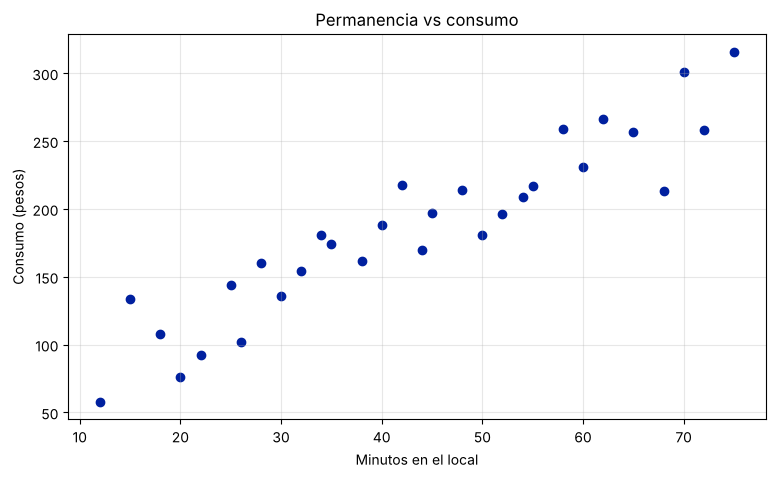

Coeficiente de correlación r: 0.9307
r cuadrada: 0.8662


In [14]:
# Ejercicio 7
x = consumo["minutos"]
y = consumo["pesos"]

# 1) Diagrama de dispersión
plt.scatter(x, y, color=AZUL)
plt.title("Permanencia vs consumo")
plt.xlabel("Minutos en el local")
plt.ylabel("Consumo (pesos)")
plt.show()

r = x.corr(y)
r2 = r**2
print("Coeficiente de correlación r:", round(r, 4))
print("r cuadrada:", round(r2, 4))

La relación es **positiva** (a más minutos, más consumo) y **fuerte** (r = 0.93, los puntos
siguen bastante bien una línea recta).

**Interpretación de r²:** el 86.6 % de la variación en el consumo se explica por los minutos que el
cliente se queda en el local.

b1 (pendiente): 3.2615
b0 (intercepto): 44.9438
Recta: consumo = 44.94 + 3.26 * minutos
Consumo estimado con 45 minutos: 191.71 pesos


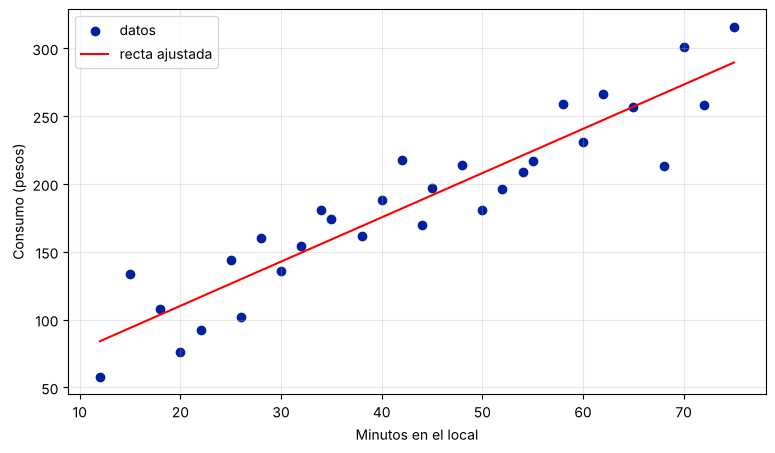

In [15]:
# 2) Recta de mínimos cuadrados
n = len(x)
b1 = ((x - x.mean()) * (y - y.mean())).sum() / ((x - x.mean())**2).sum()
b0 = y.mean() - b1 * x.mean()
print("b1 (pendiente):", round(b1, 4))
print("b0 (intercepto):", round(b0, 4))
print("Recta: consumo =", round(b0, 2), "+", round(b1, 2), "* minutos")

# Estimación para 45 minutos
estimado = b0 + b1 * 45
print("Consumo estimado con 45 minutos:", round(estimado, 2), "pesos")

# Dibujo la recta sobre los puntos
plt.scatter(x, y, color=AZUL, label="datos")
plt.plot(x, b0 + b1 * x, color="red", label="recta ajustada")
plt.xlabel("Minutos en el local")
plt.ylabel("Consumo (pesos)")
plt.legend()
plt.show()

**b₁ = 3.26:** por cada minuto más que el cliente se queda en el local, su consumo aumenta en
promedio **3.26 pesos**.

**b₀ = 44.94:** en teoría sería el consumo de alguien que se queda 0 minutos, lo cual **no tiene
sentido** en la práctica. Además, el dato más chico es de 12 minutos, así que 0 está fuera del rango
de los datos y no conviene interpretarlo.

**Estimación:** un cliente que se queda 45 minutos gastaría alrededor de **191.71 pesos**.

**Prueba de significancia de la pendiente**

- H₀: β₁ = 0 (los minutos no tienen relación lineal con el consumo)
- H₁: β₁ ≠ 0 (sí hay relación lineal)

In [16]:
# 3) Prueba de significancia de la pendiente
y_estimada = b0 + b1 * x
residuos = y - y_estimada
sce = (residuos**2).sum()          # suma de cuadrados del error
gl = n - 2
s_e = np.sqrt(sce / gl)            # error estándar de la estimación
ee_b1 = s_e / np.sqrt(((x - x.mean())**2).sum())

t_calc = b1 / ee_b1
valor_p = 2 * (1 - t.cdf(abs(t_calc), gl))   # dos colas
alfa = 0.05

print("Error estándar de b1:", round(ee_b1, 4))
print("Estadístico t:", round(t_calc, 4))
print("Grados de libertad:", gl)
print("Valor p:", valor_p)

if valor_p < alfa:
    print("Se rechaza H0")
else:
    print("No se rechaza H0")

# Comprobación con scipy
print()
print(stats.linregress(x, y))

Error estándar de b1: 0.2422
Estadístico t: 13.4651
Grados de libertad: 28
Valor p: 9.392486788328824e-14
Se rechaza H0

LinregressResult(slope=np.float64(3.2615326160169946), intercept=np.float64(44.94384207526639), rvalue=np.float64(0.9307124915795271), pvalue=np.float64(9.390199030031521e-14), stderr=np.float64(0.24222192029085238), intercept_stderr=np.float64(11.322503826800052))


**Conclusión:** t = 13.47 con 28 grados de libertad y un valor p prácticamente 0, mucho menor que
0.05, así que **se rechaza H₀**. La pendiente es significativa: sí existe una relación lineal entre
los minutos en el local y el consumo.

**¿Esto demuestra causa?** No. La regresión solo muestra que las dos variables se mueven juntas,
pero los datos son observacionales (nadie controló cuánto tiempo se quedaba cada cliente). Puede
haber otra variable detrás de las dos, por ejemplo el **número de personas en el grupo**: si un
cliente viene acompañado, se queda más tiempo platicando *y* además paga por más bebidas y comida.
En ese caso no es el tiempo el que provoca el gasto, sino el tamaño del grupo.